# 03 - Evaluación comparativa y análisis de errores

Fase *Model Verification* de Ashmore et al. (2021). Se comparan los cuatro modelos, se estudia en
qué segmentos fallan, se analiza con un modelo de lenguaje una muestra de errores de BETO y se analiza la caída de
desempeño en los contratos de 2026 (prueba temporal).

Requisitos: haber entrenado la línea base, la red neuronal y BETO (`scripts/entrenar_*.py`). Las probabilidades de BETO no
se versionan; se regeneran con `python scripts/entrenar_beto.py --solo-evaluar`.

In [1]:
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import confusion_matrix, f1_score

from secopedia.configuracion import cargar_config, ruta
from secopedia.evaluacion import calcular_metricas
from secopedia.modelos.red_neuronal import ClasificadorCNN
from secopedia.segmentos import nombre_segmento

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 140)
config = cargar_config()
carpeta_modelos = ruta(config["rutas"]["modelos"] + "/x").parent
carpeta_metricas = ruta(config["rutas"]["metricas"] + "/x").parent
carpeta_figuras = ruta(config["rutas"]["figuras"] + "/x").parent
clases = json.loads((carpeta_metricas / "clases.json").read_text(encoding="utf-8"))
C = np.array(clases)

NOMBRES_MODELOS = {
    "regresion_logistica": "TF-IDF + Reg. logística",
    "svm_lineal": "TF-IDF + SVM lineal",
    "red_neuronal": "CNN + fastText",
    "beto": "BETO",
}
modelos_clasicos = {
    "regresion_logistica": joblib.load(carpeta_modelos / "regresion_logistica.joblib"),
    "svm_lineal": joblib.load(carpeta_modelos / "svm_lineal.joblib"),
    "red_neuronal": ClasificadorCNN.cargar(carpeta_modelos / "red_neuronal" / "cnn.pt"),
}

datos, probabilidades = {}, {}
for particion in ["prueba", "prueba_temporal"]:
    df = pd.read_parquet(ruta(config["rutas"]["procesados"]) / f"{particion}.parquet")
    lemas = df["lemas"].map(" ".join)
    probabilidades[particion] = {nombre: modelo.predict_proba(lemas) for nombre, modelo in modelos_clasicos.items()}
    beto = pd.read_parquet(carpeta_metricas / f"beto_probabilidades_{particion}.parquet")
    assert (beto["id_contrato"].to_numpy() == df["id_contrato"].to_numpy()).all(), "orden distinto"
    probabilidades[particion]["beto"] = beto[clases].to_numpy()
    # Promedio simple de las probabilidades de los cuatro modelos.
    probabilidades[particion]["ensamble"] = np.mean(list(probabilidades[particion].values()), axis=0)
    datos[particion] = df
NOMBRES_MODELOS["ensamble"] = "Promedio de los 4"
print({p: len(df) for p, df in datos.items()})

{'prueba': 13128, 'prueba_temporal': 20000}


## 1. Comparación de modelos

F1 macro es la métrica principal (pesa igual cada segmento); top-3 es lo que ve el usuario en la
aplicación. El *ensamble* promedia las probabilidades de los cuatro modelos.

In [2]:
filas = []
for particion, por_modelo in probabilidades.items():
    for nombre, prob in por_modelo.items():
        filas.append({"modelo": NOMBRES_MODELOS[nombre], "particion": particion,
                      **calcular_metricas(datos[particion]["etiqueta"], prob, clases)})
comparacion = pd.DataFrame(filas).drop(columns="n")
tabla = comparacion.pivot(index="modelo", columns="particion", values=["f1_macro", "top3_accuracy", "accuracy"])
tabla = tabla.reindex([NOMBRES_MODELOS[m] for m in NOMBRES_MODELOS])
tabla

f1_macro                 top3_accuracy  \
particion                 prueba prueba_temporal        prueba   
modelo                                                           
TF-IDF + Reg. logística   0.6508          0.5361        0.8548   
TF-IDF + SVM lineal       0.6587          0.5442        0.8447   
CNN + fastText            0.6524          0.5338        0.8592   
BETO                      0.6673          0.5560        0.8713   
Promedio de los 4         0.6796          0.5640        0.8769   

                                        accuracy                  
particion               prueba_temporal   prueba prueba_temporal  
modelo                                                            
TF-IDF + Reg. logística          0.8216   0.6574          0.5770  
TF-IDF + SVM lineal              0.8196   0.6668          0.5874  
CNN + fastText                   0.8387   0.6595          0.5805  
BETO                             0.8530   0.6791          0.6022  
Promedio de los 4                0.8552   0.6879          0.6086

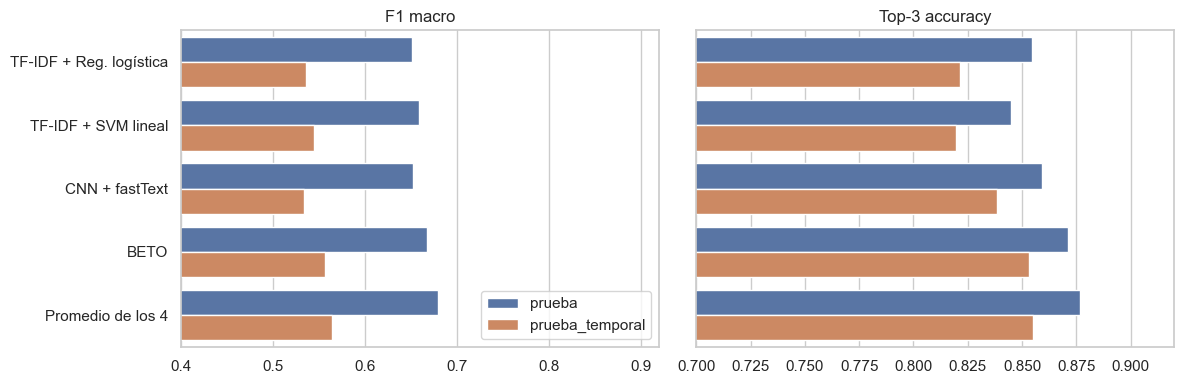

In [3]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for eje, metrica, titulo in zip(ejes, ["f1_macro", "top3_accuracy"], ["F1 macro", "Top-3 accuracy"]):
    sns.barplot(data=comparacion, y="modelo", x=metrica, hue="particion", ax=eje,
                order=list(NOMBRES_MODELOS.values()), palette=["#4C72B0", "#DD8452"])
    eje.set_title(titulo)
    eje.set_xlabel("")
    eje.set_ylabel("")
    eje.set_xlim(0.4 if metrica == "f1_macro" else 0.7, 0.92)
ejes[0].legend(title="", loc="lower right")
ejes[1].get_legend().remove()
plt.tight_layout()
fig.savefig(carpeta_figuras / "comparacion_modelos.png", dpi=150)

## 2. Desempeño por segmento (prueba)

In [4]:
y_prueba = datos["prueba"]["etiqueta"].to_numpy()
predicciones = {nombre: C[prob.argmax(axis=1)] for nombre, prob in probabilidades["prueba"].items()}
f1_clase = pd.DataFrame(
    {NOMBRES_MODELOS[m]: f1_score(y_prueba, predicciones[m], labels=clases, average=None) for m in modelos_clasicos | {"beto": None}},
    index=clases,
).round(3)
f1_clase.insert(0, "nombre", [nombre_segmento(c)[:45] for c in clases])
f1_clase.sort_values("BETO")

,nombre,TF-IDF + Reg. logística,TF-IDF + SVM lineal,CNN + fastText,BETO
14,Materiales y productos de papel,0.388,0.342,0.300,0.214
otros,Otros segmentos (poco frecuentes),0.225,0.251,0.255,0.277
60,"Instrumentos musicales, juegos, artes, artesa",0.497,0.504,0.472,0.486
81,"Servicios de ingeniería, investigación y tecn",0.457,0.475,0.447,0.501
93,Servicios políticos y de asuntos cívicos,0.589,0.581,0.572,0.575
47,Equipos de limpieza y suministros,0.555,0.571,0.593,0.578
80,"Servicios de gestión, profesionales de empres",0.586,0.598,0.565,0.593
44,"Equipos de oficina, accesorios y suministros",0.547,0.578,0.566,0.614
72,"Servicios de edificación, construcción y mant",0.625,0.629,0.621,0.638
30,"Componentes y suministros para estructuras, e",0.617,0.630,0.623,0.655


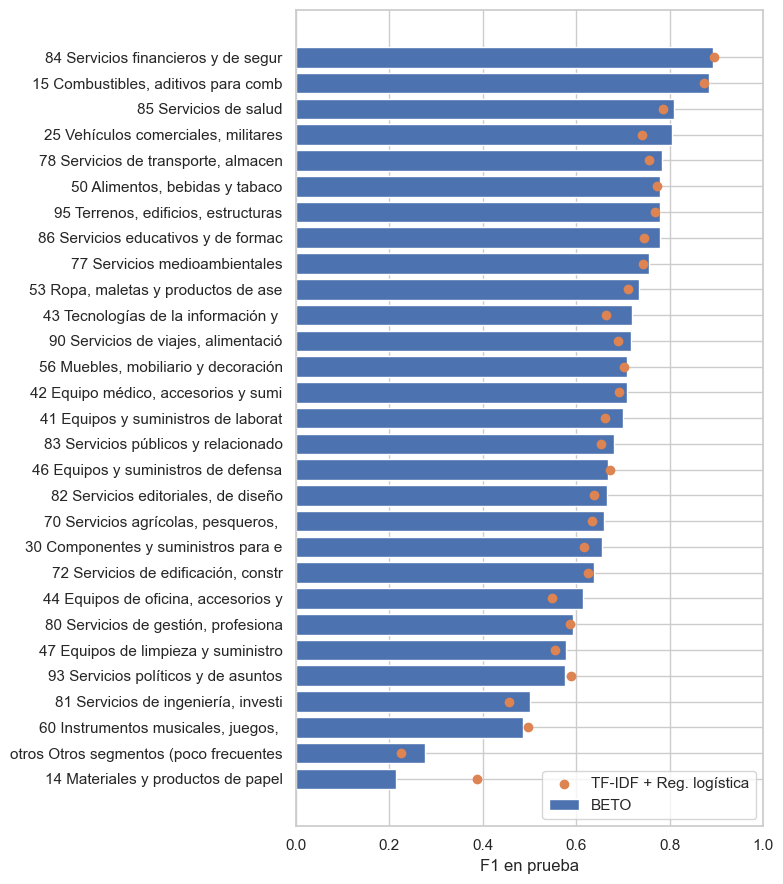

In [5]:
orden = f1_clase.sort_values("BETO").index
fig, eje = plt.subplots(figsize=(8, 9))
eje.barh([f"{c} {nombre_segmento(c)[:32]}" for c in orden], f1_clase.loc[orden, "BETO"], color="#4C72B0", label="BETO")
eje.scatter(f1_clase.loc[orden, "TF-IDF + Reg. logística"], range(len(orden)), color="#DD8452", zorder=3,
            label="TF-IDF + Reg. logística")
eje.set_xlabel("F1 en prueba")
eje.set_xlim(0, 1)
eje.legend(loc="lower right")
plt.tight_layout()
fig.savefig(carpeta_figuras / "f1_por_segmento.png", dpi=150)

## 3. Pares de segmentos que más se confunden (BETO)

In [6]:
matriz = confusion_matrix(y_prueba, predicciones["beto"], labels=clases)
np.fill_diagonal(matriz, 0)
pares = pd.DataFrame(
    [(matriz[i, j], clases[i], clases[j]) for i in range(len(clases)) for j in range(len(clases))],
    columns=["errores", "real", "predicho"],
).sort_values("errores", ascending=False).head(12)
pares["nombre_real"] = pares["real"].map(nombre_segmento)
pares["nombre_predicho"] = pares["predicho"].map(nombre_segmento)
pares.reset_index(drop=True)

,errores,real,predicho,nombre_real,nombre_predicho
0,171,14,44,Materiales y productos de papel,"Equipos de oficina, accesorios y suministros"
1,70,70,77,"Servicios agrícolas, pesqueros, forestales y de fauna",Servicios medioambientales
2,65,81,43,"Servicios de ingeniería, investigación y tecnología",Tecnologías de la información y telecomunicaciones
3,56,95,72,"Terrenos, edificios, estructuras y vías","Servicios de edificación, construcción y mantenimiento"
4,53,81,72,"Servicios de ingeniería, investigación y tecnología","Servicios de edificación, construcción y mantenimiento"
5,53,46,53,"Equipos y suministros de defensa, orden público y seguridad","Ropa, maletas y productos de aseo personal"
6,49,80,81,"Servicios de gestión, profesionales de empresa y administrativos","Servicios de ingeniería, investigación y tecnología"
7,41,50,90,"Alimentos, bebidas y tabaco","Servicios de viajes, alimentación, alojamiento y entretenimiento"
8,39,30,72,"Componentes y suministros para estructuras, edificación y obras civiles","Servicios de edificación, construcción y mantenimiento"
9,38,41,42,"Equipos y suministros de laboratorio, medición y pruebas","Equipo médico, accesorios y suministros"


## 4. Confianza del modelo y acierto

Si la confianza de BETO es útil, los contratos con probabilidad alta deberían acertarse casi siempre.
Esto respalda el modo *Auditar*: un error con confianza muy alta suele ser una etiqueta mal puesta.

In [7]:
confianza = probabilidades["prueba"]["beto"].max(axis=1)
acierto = predicciones["beto"] == y_prueba
tramos = pd.cut(confianza, [0, 0.5, 0.7, 0.9, 0.97, 1.0], include_lowest=True)
calibracion = pd.DataFrame({"tramo": tramos, "acierto": acierto}).groupby("tramo", observed=True)["acierto"].agg(
    contratos="size", exactitud="mean").round(3)
calibracion["confianza_media"] = pd.Series(confianza).groupby(tramos, observed=True).mean().round(3).to_numpy()
calibracion

,contratos,exactitud,confianza_media
tramo,,,
"(-0.001, 0.5]",2430,0.314,0.377
"(0.5, 0.7]",2500,0.511,0.599
"(0.7, 0.9]",3311,0.710,0.812
"(0.9, 0.97]",2910,0.890,0.940
"(0.97, 1.0]",1977,0.979,0.983


## 5. Acuerdo entre modelos

Cuando los cuatro modelos, que ven el texto de formas muy distintas, coinciden entre sí pero no con
la etiqueta registrada, es probable que la etiqueta esté mal.

In [8]:
coinciden = np.all([predicciones[m] == predicciones["beto"] for m in modelos_clasicos], axis=0)
sospechosos = coinciden & ~acierto
print(f"Los 4 modelos coinciden en {coinciden.mean():.1%} de los contratos")
print(f"Coinciden entre sí y difieren de la etiqueta: {sospechosos.sum():,} "
      f"({sospechosos.sum() / (~acierto).sum():.1%} de los errores de BETO)")
ejemplos = datos["prueba"].loc[sospechosos, ["objeto_del_contrato", "etiqueta"]].assign(
    predicho=predicciones["beto"][sospechosos], confianza=confianza[sospechosos].round(3))
ejemplos.sort_values("confianza", ascending=False).head(10)

Los 4 modelos coinciden en 69.7% de los contratos
Coinciden entre sí y difieren de la etiqueta: 1,790 (42.5% de los errores de BETO)


,objeto_del_contrato,etiqueta,predicho,confianza
4381,CONTRATAR LA PÓLIZA DE SEGURO DE VIDA PARA LOS HONORABLES CONCEJALES; PERSONERA Y EL SEÑOR ALCALDE DEL MUNICIPIO DE GALAPA ATLÁNTICO VIG...,93,84,0.995
849,REALIZAR EL SUMINISTRO DE PÓLIZAS DE SEGUROS; ACCIDENTES PERSONALES ESCUELAS DEPORTIVAS; RESPONSABILIDAD CIVIL EXTRACONTRACTUAL; TODO RI...,80,84,0.995
5671,CONVENIO INTERADMINISTRATIVO PARA LA PRESTACIÓN DE SERVICIOS DE SALUD DEL PRIMER NIVEL DE ATENCIÓN A LA POBLACIÓN NO AFILIADA Y POBLACIÓ...,46,85,0.990
9407,CONTRATAR EL SUMINISTRO DE PRODUCTOS ALIMENTICIOS PARA EL PROYECTO PRODUCTIVO DE PANADERÍA Y ASÍ CUBRIR LAS NECESIDADES QUE DEMANDAN LOS...,47,50,0.987
3460,Compra de póliza de cumplimiento; salarios y prestaciones sociales; calidad del servicio y responsabilidad civil extracontractual; para ...,93,84,0.987
8326,ADQUISICIÓN DE LLANTAS Y BATERIAS PARA LOS AUTOMOTORES DEL BIINF55 Y GAULA HUILA; UNIDADES CENTRALIZADAS POR LA CENAC REGIONAL NEIVA; PA...,otros,25,0.986
6916,PRESTACIÓN DE SERVICIOS POR PARTE DE LA E.S.E HOSPITAL SAN RAFAEL PARA LA EJECUCIÓN DE LAS ACCIONES DE PROMOCIÓN DE LA SALUD Y GESTIÓN D...,81,85,0.985
8076,Prestación de servicios de capacitación dirigida a los servidores públicos de la Superintendencia de \nIndustria y Comercio para el desa...,60,86,0.983
4138,DESARROLLO DE ACTIVIDADES DE INTERES CONJUNTO PARA EL SOSTENIMIENTO DE PARCELAS AGROECOLOGICAS; EN BENEFICIO DE LAS FAMILIAS ASOCIADAS A...,93,70,0.983
8829,COMPRA DE MOTOCICLETAS PARA LA FUERZA PÚBLICA - EJERCITO NACIONAL; PARA EL FORTALECIMIENTO INSTITUCIONAL DE SUS CAPACIDADES OPERATIVAS; ...,46,25,0.982


## 6. Análisis automático de 100 errores de BETO con un modelo de lenguaje

Se tomó una muestra aleatoria (semilla 42) de 100 contratos de prueba en los que la predicción de BETO no coincide
con el segmento registrado. Un modelo de lenguaje leyó cada texto, junto con el segmento registrado y el predicho,
y lo clasificó en una de cuatro categorías:

- **Etiqueta incorrecta:** el código registrado por la entidad no parece corresponder al texto; la predicción es mejor.
- **Ambiguo:** el contrato mezcla varios bienes o servicios, o dos segmentos son igual de válidos
  (por ejemplo, "papelería y útiles de oficina" en 14 o en 44).
- **Error del modelo:** la etiqueta parece correcta y el modelo se equivoca.
- **Texto genérico:** el texto no dice qué se compra ("aunar esfuerzos...", "materiales de formación").

**Alcance:** es una clasificación automática de una sola pasada, sin verificación humana. El modelo de lenguaje conocía
la predicción de BETO, lo que puede sesgarlo a su favor. Con 100 casos, los porcentajes son aproximados.

In [9]:
prueba = datos["prueba"].assign(predicho=predicciones["beto"], confianza=confianza)
muestra = prueba[prueba["predicho"] != prueba["etiqueta"]].sample(100, random_state=42).reset_index(drop=True)

ETIQUETA_INCORRECTA, AMBIGUO, ERROR_MODELO, GENERICO = (
    "Etiqueta incorrecta", "Ambiguo", "Error del modelo", "Texto genérico")
categorias = {}
for i in [1, 4, 6, 7, 12, 14, 19, 22, 31, 33, 35, 36, 44, 45, 46, 47, 49, 60, 61, 62, 63, 64, 65, 66, 68, 70,
          72, 76, 79, 83, 86, 88, 91, 92, 93, 99]:
    categorias[i] = ETIQUETA_INCORRECTA
for i in [8, 9, 11, 20, 26, 28, 37, 59, 75, 78, 98]:
    categorias[i] = ERROR_MODELO
for i in [2, 23, 42, 57, 73, 80, 82]:
    categorias[i] = GENERICO
muestra["categoria"] = [categorias.get(i, AMBIGUO) for i in range(len(muestra))]

# Comprobación de que la muestra es la misma que se revisó.
assert "PÓLIZAS DE SEGUROS" in muestra.loc[60, "objeto_del_contrato"]
assert "CORRESPONDENCIA" in muestra.loc[33, "objeto_del_contrato"]

resumen_manual = muestra.groupby("categoria").agg(contratos=("categoria", "size"),
                                                  confianza_media=("confianza", "mean")).round(3)
resumen_manual.sort_values("contratos", ascending=False)

,contratos,confianza_media
categoria,,
Ambiguo,46,0.595
Etiqueta incorrecta,36,0.621
Error del modelo,11,0.434
Texto genérico,7,0.433


In [10]:
for categoria in [ETIQUETA_INCORRECTA, AMBIGUO, ERROR_MODELO, GENERICO]:
    print(f"--- {categoria}")
    for _, fila in muestra[muestra["categoria"] == categoria].head(4).iterrows():
        texto = " ".join(fila["objeto_del_contrato"].split())[:110]
        print(f"  registrado {fila['etiqueta']:>5} | predicho {fila['predicho']:>5} ({fila['confianza']:.2f}) | {texto}")

--- Etiqueta incorrecta
  registrado    30 | predicho    80 (0.58) | AUNAR ESFUERZOS Y RECURSOS ADMINISTRATIVOS; FINANCIEROS Y TÉCNICOS; ENTRE EL MUNICIPIO DE YUMBO Y EL FONDO MIX
  registrado    81 | predicho    43 (0.83) | ADQUISICIÓN DEL HARDWARE Y SOFTWARE LA PLATAFORMA FIREWALL DEL FONDO ROTATORIO DE LA POLICIA
  registrado    14 | predicho    82 (0.91) | SERVICIOS DE FOTOCOPIADO PARA LAS DEPENDENCIAS DEL ICBF REGIONAL HUILA Y SUS CENTROS ZONALES; CON EL FIN DE GA
  registrado    81 | predicho    90 (0.23) | SUMINISTRO Y APOYO LOGÍSTICO PARA LA PARTICIPACIÓN DEL INSTITUTO DE CULTURA Y TURISMO DEL MUNICIPIO DE SAN GIL
--- Ambiguo
  registrado    60 | predicho    44 (0.45) | SUMINISTRO DE PAPELERÍA; ÚTILES DE OFICINA; INSUMOS DE ASEO; LIMPIEZA; CONTENEDORES DE BASURA; TÓNER PARA LAS 
  registrado    93 | predicho    77 (0.77) | Aunar esfuerzos técnicos; administrativos y financieros para el desarrollo de acciones del Plan de Manejo del 
  registrado    14 | predicho    44 (0.58) | S

**Conclusión del análisis.** Según el modelo de lenguaje, la mayoría de los desacuerdos no son fallas claras de BETO:
el 46% son contratos ambiguos, el 36% tiene una etiqueta que parece incorrecta, el 7% son textos genéricos y el 11% son
errores claros del modelo (intervalo de confianza del 95%: entre 6% y 19%, por el tamaño de la muestra). El intervalo
no incluye los errores del propio modelo de lenguaje.

El resultado apunta en la misma dirección que dos evidencias que no dependen de ese modelo: 8.771 textos idénticos están
registrados con segmentos distintos, y en el 42,5% de los errores de BETO los cuatro clasificadores coinciden entre sí y
contradicen la etiqueta. En conjunto, sugieren que el ruido y la ambigüedad de los códigos registrados explican una parte
importante de los errores medidos. No permiten calcular cuánto mejoraría el F1 con etiquetas corregidas; para eso haría
falta una revisión hecha por personas, sin conocer la predicción.

## 7. Caída en la prueba temporal (2026) y corrección por distribución de clases

Todos los modelos bajan en 2026. Una causa es el cambio de distribución: se entrenaron con un tope de
4.000 contratos por clase (clases casi balanceadas), pero en la realidad el segmento 80 es mucho más
frecuente que, por ejemplo, el 95. El modelo sobrestima las clases pequeñas.

Corrección: multiplicar las probabilidades por `p_real(clase) / p_entrenamiento(clase)` y
renormalizar. `p_real` se calcula **solo con contratos anteriores a 2026**, así que no usa
información de la prueba temporal.

In [11]:
limpios = pd.read_parquet(ruta(config["rutas"]["limpios"]), columns=["codigo_de_categoria_principal", "fecha_de_firma"])
limpios = limpios[limpios["fecha_de_firma"] < pd.Timestamp(config["etiquetas"]["fecha_corte_temporal"])]
segmento = limpios["codigo_de_categoria_principal"].str[3:5]
p_real = segmento.where(segmento.isin(clases), "otros").value_counts(normalize=True).reindex(clases).to_numpy()
p_entrenamiento = (pd.read_parquet(ruta(config["rutas"]["procesados"]) / "entrenamiento.parquet")["etiqueta"]
                   .value_counts(normalize=True).reindex(clases).to_numpy())


def ajustar_a_priori(prob):
    ajustada = prob * p_real / p_entrenamiento
    return ajustada / ajustada.sum(axis=1, keepdims=True)


y_temporal = datos["prueba_temporal"]["etiqueta"]
filas = []
for nombre, prob in probabilidades["prueba_temporal"].items():
    for version, p in [("original", prob), ("ajustada", ajustar_a_priori(prob))]:
        m = calcular_metricas(y_temporal, p, clases)
        filas.append({"modelo": NOMBRES_MODELOS[nombre], "version": version, "f1_macro": m["f1_macro"],
                      "top3_accuracy": m["top3_accuracy"], "accuracy": m["accuracy"]})
ajuste = pd.DataFrame(filas).pivot(index="modelo", columns="version", values=["f1_macro", "top3_accuracy", "accuracy"])
ajuste.reindex([NOMBRES_MODELOS[m] for m in NOMBRES_MODELOS])

f1_macro          top3_accuracy          accuracy  \
version                 ajustada original      ajustada original ajustada   
modelo                                                                      
TF-IDF + Reg. logística   0.5679   0.5361        0.8728   0.8216   0.6289   
TF-IDF + SVM lineal       0.5707   0.5442        0.8554   0.8196   0.6313   
CNN + fastText            0.5643   0.5338        0.8757   0.8387   0.6296   
BETO                      0.5909   0.5560        0.8883   0.8530   0.6534   
Promedio de los 4         0.5946   0.5640        0.8921   0.8552   0.6595   

                                  
version                 original  
modelo                            
TF-IDF + Reg. logística   0.5770  
TF-IDF + SVM lineal       0.5874  
CNN + fastText            0.5805  
BETO                      0.6022  
Promedio de los 4         0.6086

In [12]:
f1_temporal = f1_score(y_temporal, C[probabilidades["prueba_temporal"]["beto"].argmax(axis=1)], labels=clases, average=None)
cambio = pd.DataFrame({"nombre": [nombre_segmento(c)[:45] for c in clases],
                       "f1_prueba": f1_clase["BETO"].to_numpy(), "f1_2026": f1_temporal.round(3),
                       "pct_en_2026": (100 * y_temporal.value_counts(normalize=True).reindex(clases).fillna(0)).round(1).to_numpy()},
                      index=clases)
cambio["diferencia"] = (cambio["f1_2026"] - cambio["f1_prueba"]).round(3)
cambio.sort_values("diferencia").head(10)

,nombre,f1_prueba,f1_2026,pct_en_2026,diferencia
95,"Terrenos, edificios, estructuras y vías",0.779,0.316,1.0,-0.463
83,Servicios públicos y relacionados con el sect,0.681,0.293,0.8,-0.388
70,"Servicios agrícolas, pesqueros, forestales y",0.660,0.350,1.0,-0.310
86,Servicios educativos y de formación,0.778,0.511,1.2,-0.267
82,"Servicios editoriales, de diseño, artes gráfi",0.665,0.410,0.8,-0.255
30,"Componentes y suministros para estructuras, e",0.655,0.427,1.4,-0.228
56,"Muebles, mobiliario y decoración",0.709,0.501,1.0,-0.208
50,"Alimentos, bebidas y tabaco",0.779,0.609,2.0,-0.170
77,Servicios medioambientales,0.755,0.606,1.6,-0.149
78,"Servicios de transporte, almacenaje y correo",0.783,0.637,1.8,-0.146


## 7b. Curva de aprendizaje: ¿más datos ayudarían?

Generada con `scripts/curva_aprendizaje.py`. Se varía el tope de contratos por clase (de 500 a sin tope:
284.199 contratos anteriores a 2026 que no están en validación ni prueba) y se entrenan la regresión
logística y la CNN con los mismos hiperparámetros. Las probabilidades se ajustan a la distribución
del conjunto evaluado para que los tamaños sean comparables.

particion         prueba                         prueba_temporal  \
modelo    CNN + fastText TF-IDF + Reg. logística  CNN + fastText   
contratos                                                          
14500              0.607                   0.588           0.522   
29000              0.623                   0.612           0.549   
58000              0.643                   0.634           0.564   
105017             0.655                   0.651           0.572   
148868             0.657                   0.657           0.574   
198676             0.660                   0.648           0.582   
284199             0.657                   0.639           0.581   

particion                          
modelo    TF-IDF + Reg. logística  
contratos                          
14500                       0.496  
29000                       0.531  
58000                       0.550  
105017                      0.569  
148868                      0.581  
198676                      0.570  
284199                      0.557

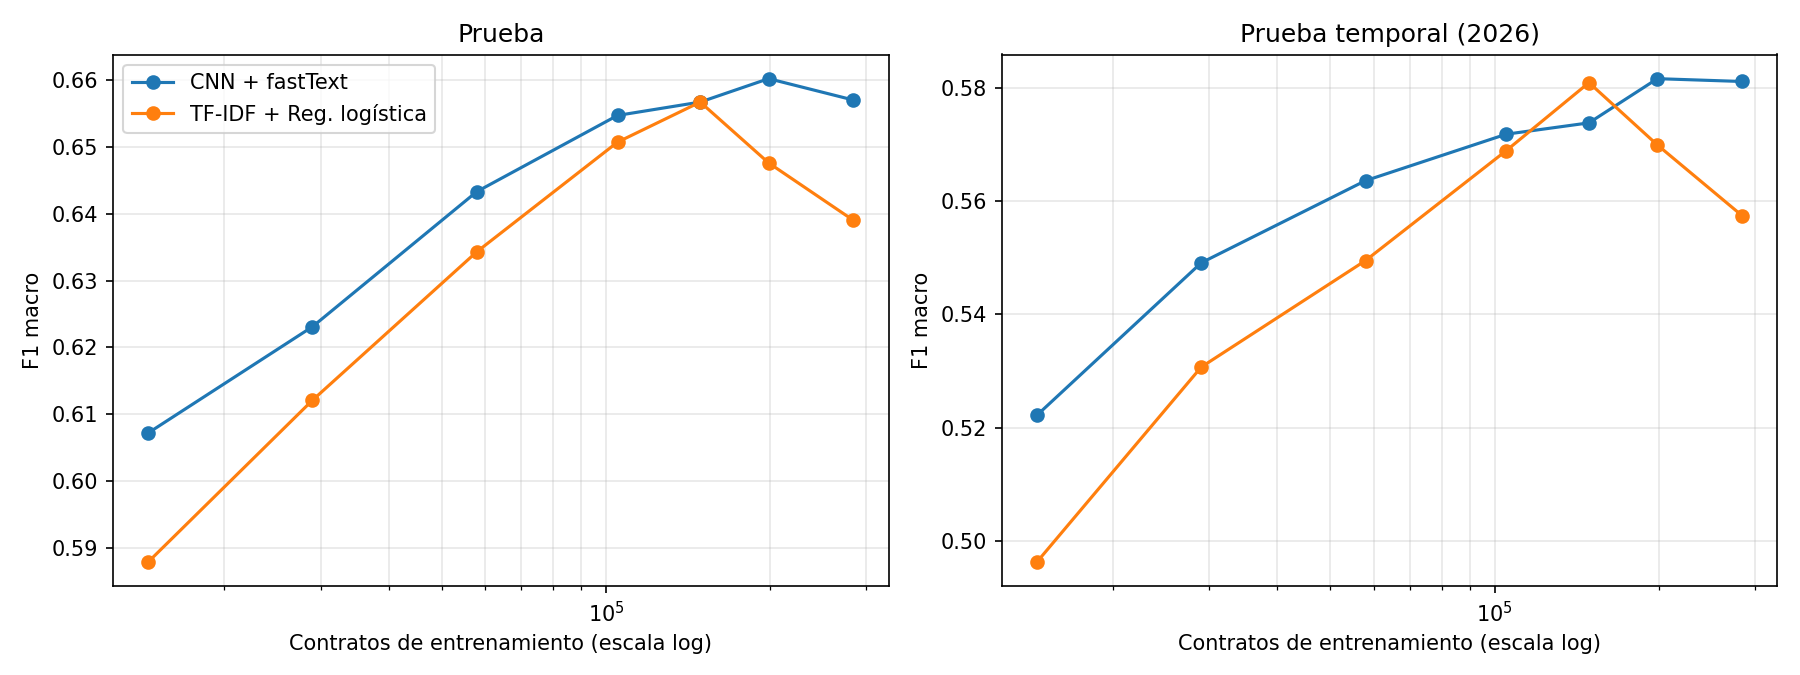

In [13]:
from IPython.display import Image, display

curva = pd.read_csv(carpeta_metricas / "curva_aprendizaje.csv")
display(curva.pivot_table(index="contratos", columns=["particion", "modelo"], values="f1_macro").round(3))
display(Image(filename=str(carpeta_figuras / "curva_aprendizaje.png")))

## 8. Conclusiones

1. **BETO es el mejor modelo individual** (prueba: F1 macro 0,667 y top-3 0,871), pero la ventaja sobre TF-IDF es pequeña (1 a 2 puntos de F1). Buena parte de la tarea se resuelve con palabras clave ("póliza", "combustible", "papelería"). El **promedio de los cuatro modelos** mejora un poco más (F1 0,680 y top-3 0,877), probablemente porque cada representación se equivoca en contratos distintos.
2. **Los errores se concentran en segmentos que se solapan en el propio catálogo UNSPSC**: 14 (papel) contra 44 (oficina) es la confusión más frecuente, con 171 casos, porque "papelería y útiles de oficina" cabe en ambos. Le siguen 70 contra 77 (agrícola y medioambiental), 81 contra 43 y 72 (ingeniería contra TI y construcción) y la clase "otros", que mezcla segmentos muy distintos.
3. **La confianza de BETO es informativa**: con probabilidad mayor a 0,97 acierta el 97,9% de las veces; por debajo de 0,5 solo el 31%. Esto respalda mostrar el top 3 al usuario y usar la confianza en el modo Auditar.
4. **Muchos "errores" parecen etiquetas mal puestas**: en el 42,5% de los fallos de BETO los cuatro modelos coinciden entre sí y contradicen la etiqueta. Un análisis automático de 100 errores con un modelo de lenguaje, sin verificación humana, clasificó el 46% como ambiguos, el 36% como etiqueta incorrecta, el 7% como textos genéricos y solo el **11% como errores claros del modelo**. Esto sugiere que la calidad de las etiquetas limita cuánto se puede mejorar.
5. **En 2026 todos los modelos bajan** (BETO: F1 0,667 a 0,556), sobre todo en segmentos pequeños como 95, 83 y 70. Una causa es el cambio de distribución: se entrenó con clases casi balanceadas y en la realidad son muy desiguales. **Ajustar las probabilidades a la distribución real** (calculada con contratos anteriores a 2026) recupera unos 3,5 de los 11 puntos sin usar datos de 2026: el F1 macro de BETO sube de 0,556 a 0,591 y el top-3 de 0,853 a 0,888. El resto no se puede atribuir solo al paso del tiempo, porque la prueba temporal cambia a la vez la fecha y la mezcla de clases.
6. **Más datos ya no ayudan.** La curva de aprendizaje sube con fuerza hasta unos 100 mil contratos (el tamaño actual) y luego se aplana: triplicar los datos (284 mil) mejora la CNN menos de 1 punto de F1, y la regresión logística incluso empeora por el desbalance. Junto con el punto 4, esto sugiere que **la calidad de las etiquetas limita el resultado más que la cantidad de datos**, y ayuda a entender por qué BETO supera por poco a los modelos simples. La curva no se calculó con BETO, y quedan sin medir otras causas, como darle el texto sin tildes.

**Recomendaciones:** el ajuste por distribución de clases ya se aplica en la aplicación; mantener el top 3 como salida principal y usar el modo Auditar con confianza alta (0,9 o más) para encontrar contratos mal codificados.